# PRDM9 recombination feature generation (production)

This notebook builds the **recombination / DSB-hotspot feature family** for all three window sets:

- `prdm9`
- `datasetA_matched`
- `datasetB_global`

## Production feature definition

The exploratory notebook mixed overlap, raw distance, and neighborhood summaries. For the publication-ready version, the main merge-ready features are restricted to the biologically cleaner core:

- `recombination__nearest_hotspot_proximity`
- `recombination__nearest_hotspot_center_proximity`
- `recombination__density_covfrac_10kb`
- `recombination__density_covfrac_50kb`
- `recombination__density_covfrac_100kb`

### Important scaling decision

Raw distance in base pairs or kilobases is **not** exported as a main feature, because it would sit on a very different numeric scale from the other feature families and distort downstream plots.

Instead, the main distance-like features are exported as **bounded proximity transforms**:

\[
\mathrm{proximity}(d) = \frac{1}{1 + d / s}
\]

where:

- \(d\) is the raw distance in bp
- \(s = 10{,}000\) bp is the proximity scale

This yields values in \((0, 1]\), with:

- overlap / zero distance → `1.0`
- 10 kb away → `0.5`
- 100 kb away → `~0.091`

The **raw distances** in bp and kb are still written to the QC/debug parquet and used in validation plots.

## Output structure

The notebook writes:

- merge-ready parquet
- QC/debug parquet
- one parquet per window set
- window table
- summary / effect tables
- metadata JSON
- publication-style validation figures
- rich log file


In [1]:

# ------------------------------------------------------------------
# Imports and configuration
# ------------------------------------------------------------------
import os

# Avoid BLAS / OpenMP oversubscription when using many worker processes
for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = "1"

import gc
import json
import logging
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from tqdm.auto import tqdm
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich.logging import RichHandler
from IPython.display import display

console = Console()

N_CPUS = min(64, os.cpu_count() or 1)
CANONICAL_ONLY = True
CHUNK_SIZE = 5000

SAMPLING_DIR = Path("data_prdm9_sampling_production")
PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASET_A_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASET_B_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

RECOMB_BED = Path("meiotic_recombination/meiotic_recombination_DSB_map_hg38.bed")

RADII_BP = [10_000, 50_000, 100_000]
PROXIMITY_SCALE_BP = 10_000
FAR_DISTANCE_BP = 1_000_000_000

OUTDIR = Path("data_prdm9_recombination_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
FEATDIR = OUTDIR / "features"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for p in [OUTDIR, FIGDIR, TABDIR, FEATDIR, METADIR, LOGDIR]:
    p.mkdir(parents=True, exist_ok=True)

ALL_PARQUET = FEATDIR / "recombination_features.parquet"
DEBUG_PARQUET = FEATDIR / "recombination_features_with_qc.parquet"
PRDM9_PARQUET = FEATDIR / "recombination_features.prdm9.parquet"
DATASETA_PARQUET = FEATDIR / "recombination_features.datasetA_matched.parquet"
DATASETB_PARQUET = FEATDIR / "recombination_features.datasetB_global.parquet"

WINDOWS_TABLE = TABDIR / "all_windows.tsv"
HOTSPOT_TABLE = TABDIR / "recombination_hotspots_merged.tsv"
SUMMARY_TABLE = TABDIR / "recombination_windowset_summary.tsv"
EFFECT_TABLE = TABDIR / "recombination_effect_summary.tsv"
HOTSPOT_META_TABLE = TABDIR / "recombination_hotspot_metadata.tsv"

RUN_METADATA_JSON = METADIR / "run_metadata.json"
LOG_PATH = LOGDIR / "recombination_feature_generation.log"

# Plotting defaults
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.frameon": False,
    "font.size": 10,
})

SET_ORDER = ["prdm9", "datasetA_matched", "datasetB_global"]
SET_LABELS = {
    "prdm9": "PRDM9",
    "datasetA_matched": "A matched",
    "datasetB_global": "B global",
}
SET_COLORS = {
    "prdm9": "#2f6db3",
    "datasetA_matched": "#d07c2c",
    "datasetB_global": "#4c9a5f",
}

MAIN_FEATURES = [
    "recombination__nearest_hotspot_proximity",
    "recombination__nearest_hotspot_center_proximity",
    "recombination__density_covfrac_10kb",
    "recombination__density_covfrac_50kb",
    "recombination__density_covfrac_100kb",
]

DEBUG_FEATURES = [
    "recombination__nearest_hotspot_distance_bp",
    "recombination__nearest_hotspot_distance_kb",
    "recombination__nearest_hotspot_center_distance_bp",
    "recombination__nearest_hotspot_center_distance_kb",
    "recombination__inside_hotspot",
    "recombination__density_hits_10kb",
    "recombination__density_hits_50kb",
    "recombination__density_hits_100kb",
    "recombination__density_covered_bp_10kb",
    "recombination__density_covered_bp_50kb",
    "recombination__density_covered_bp_100kb",
]

logger = logging.getLogger("prdm9_recombination")
logger.setLevel(logging.INFO)
logger.handlers.clear()

rich_handler = RichHandler(console=console, rich_tracebacks=True, markup=True, show_path=False)
rich_handler.setLevel(logging.INFO)
file_handler = logging.FileHandler(LOG_PATH, mode="w")
file_handler.setLevel(logging.INFO)

formatter = logging.Formatter("%(asctime)s | %(levelname)s | %(message)s")
rich_handler.setFormatter(formatter)
file_handler.setFormatter(formatter)

logger.addHandler(rich_handler)
logger.addHandler(file_handler)

logger.info("Starting PRDM9 recombination feature generation notebook")
logger.info("N_CPUS=%d | CHUNK_SIZE=%d | PROXIMITY_SCALE_BP=%d", N_CPUS, CHUNK_SIZE, PROXIMITY_SCALE_BP)
logger.info("Sampling dir: %s", SAMPLING_DIR)
logger.info("Recombination BED: %s", RECOMB_BED)


[04/17/26 10:14:45] INFO     2026-04-17 10:14:45,944 | INFO | Starting PRDM9 recombination feature generation      
                             notebook

                    INFO     2026-04-17 10:14:45,950 | INFO | N_CPUS=64 | CHUNK_SIZE=5000 |                        
                             PROXIMITY_SCALE_BP=10000

                    INFO     2026-04-17 10:14:45,951 | INFO | Sampling dir: data_prdm9_sampling_production

                    INFO     2026-04-17 10:14:45,952 | INFO | Recombination BED:                                   
                             meiotic_recombination/meiotic_recombination_DSB_map_hg38.bed

In [2]:

# ------------------------------------------------------------------
# Utility helpers
# ------------------------------------------------------------------
def canonical_chromosomes():
    return [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]


def read_bed3(path, windowset_name):
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = pd.to_numeric(df["Start"], errors="raise").astype(np.int64)
    df["End"] = pd.to_numeric(df["End"], errors="raise").astype(np.int64)

    if CANONICAL_ONLY:
        df = df[df["Chromosome"].isin(canonical_chromosomes())].copy()

    if df.empty:
        raise ValueError(f"{path} produced no windows after filtering")

    bad = df.loc[df["End"] <= df["Start"]]
    if not bad.empty:
        raise ValueError(f"{path} contains non-positive windows:\n{bad.head()}")

    df["WindowSet"] = windowset_name
    return df


def add_window_id(df, start_id):
    df = df.copy()
    df["window_id"] = np.arange(start_id, start_id + len(df), dtype=np.int64)
    df["window_length_bp"] = (df["End"] - df["Start"]).astype(np.int64)
    return df


def merge_sorted_intervals(starts, ends):
    if len(starts) == 0:
        return np.empty(0, dtype=np.int64), np.empty(0, dtype=np.int64)

    merged_starts = [int(starts[0])]
    merged_ends = [int(ends[0])]

    for s, e in zip(starts[1:], ends[1:]):
        s = int(s)
        e = int(e)
        if s <= merged_ends[-1]:
            if e > merged_ends[-1]:
                merged_ends[-1] = e
        else:
            merged_starts.append(s)
            merged_ends.append(e)

    return np.asarray(merged_starts, dtype=np.int64), np.asarray(merged_ends, dtype=np.int64)


def read_recombination_bed(path):
    raw = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    raw["Chromosome"] = raw["Chromosome"].astype(str)
    raw["Start"] = pd.to_numeric(raw["Start"], errors="coerce").astype("Int64")
    raw["End"] = pd.to_numeric(raw["End"], errors="coerce").astype("Int64")

    meta = {
        "path": str(path),
        "n_raw_rows": int(len(raw)),
    }

    raw = raw.dropna().copy()
    raw["Start"] = raw["Start"].astype(np.int64)
    raw["End"] = raw["End"].astype(np.int64)
    raw = raw.loc[raw["End"] > raw["Start"]].copy()

    if CANONICAL_ONLY:
        raw = raw[raw["Chromosome"].isin(canonical_chromosomes())].copy()

    meta["n_after_basic_qc"] = int(len(raw))

    raw = raw.drop_duplicates(["Chromosome", "Start", "End"]).sort_values(
        ["Chromosome", "Start", "End"], kind="mergesort"
    ).reset_index(drop=True)

    meta["n_after_exact_dedup"] = int(len(raw))

    merged_chunks = []
    for chrom, sub in raw.groupby("Chromosome", sort=False):
        starts = sub["Start"].to_numpy(np.int64)
        ends = sub["End"].to_numpy(np.int64)
        mstarts, mends = merge_sorted_intervals(starts, ends)
        merged_chunks.append(pd.DataFrame({
            "Chromosome": chrom,
            "Start": mstarts,
            "End": mends,
        }))

    merged = pd.concat(merged_chunks, ignore_index=True) if merged_chunks else pd.DataFrame(
        columns=["Chromosome", "Start", "End"]
    )
    merged = merged.sort_values(["Chromosome", "Start", "End"], kind="mergesort").reset_index(drop=True)
    merged["hotspot_id"] = np.arange(len(merged), dtype=np.int64)
    merged["hotspot_length_bp"] = (merged["End"] - merged["Start"]).astype(np.int64)
    merged["hotspot_center_bp"] = ((merged["Start"] + merged["End"]) // 2).astype(np.int64)

    meta["n_merged_hotspots"] = int(len(merged))
    meta["median_hotspot_length_bp"] = float(merged["hotspot_length_bp"].median()) if len(merged) else 0.0
    meta["mean_hotspot_length_bp"] = float(merged["hotspot_length_bp"].mean()) if len(merged) else 0.0
    meta["chromosomes_present"] = sorted(merged["Chromosome"].unique().tolist())

    return raw.reset_index(drop=True), merged, meta


def build_hotspot_registry(merged_hotspots):
    registry = {}
    for chrom, sub in merged_hotspots.groupby("Chromosome", sort=False):
        starts = sub["Start"].to_numpy(np.int64)
        ends = sub["End"].to_numpy(np.int64)
        centers = sub["hotspot_center_bp"].to_numpy(np.int64)
        lengths = (ends - starts).astype(np.int64)
        prefix_bp = np.zeros(len(lengths) + 1, dtype=np.int64)
        prefix_bp[1:] = np.cumsum(lengths, dtype=np.int64)

        registry[chrom] = {
            "starts": starts,
            "ends": ends,
            "centers": centers,
            "prefix_bp": prefix_bp,
            "n_hotspots": int(len(starts)),
        }
    return registry


def distance_to_proximity(distance_bp, scale_bp=PROXIMITY_SCALE_BP):
    distance_bp = np.asarray(distance_bp, dtype=np.float64)
    prox = 1.0 / (1.0 + (distance_bp / float(scale_bp)))
    return prox.astype(np.float32)


def nearest_interval_distance_batch(wstart, wend, starts, ends, far_bp=FAR_DISTANCE_BP):
    if len(starts) == 0:
        return np.full(len(wstart), far_bp, dtype=np.int64)

    out = np.empty(len(wstart), dtype=np.int64)
    for i, (ws, we) in enumerate(zip(wstart, wend)):
        idx_next = np.searchsorted(starts, we, side="left")
        idx_prev = idx_next - 1

        dist = far_bp

        if idx_prev >= 0:
            if ends[idx_prev] > ws:
                out[i] = 0
                continue
            dist = min(dist, max(0, int(ws - ends[idx_prev])))

        if idx_next < len(starts):
            dist = min(dist, max(0, int(starts[idx_next] - we)))

        out[i] = dist

    return out


def nearest_center_distance_batch(wcenter, centers, far_bp=FAR_DISTANCE_BP):
    if len(centers) == 0:
        return np.full(len(wcenter), far_bp, dtype=np.int64)

    out = np.empty(len(wcenter), dtype=np.int64)
    for i, wc in enumerate(wcenter):
        idx = np.searchsorted(centers, wc, side="left")
        dist = far_bp
        if idx < len(centers):
            dist = min(dist, abs(int(centers[idx]) - int(wc)))
        if idx > 0:
            dist = min(dist, abs(int(centers[idx - 1]) - int(wc)))
        out[i] = dist
    return out


def region_overlap_count_and_coverage(region_start, region_end, starts, ends):
    if len(starts) == 0 or region_end <= region_start:
        return 0, 0

    left = np.searchsorted(ends, region_start, side="right")
    right = np.searchsorted(starts, region_end, side="left")
    if right <= left:
        return 0, 0

    cov = 0
    count = 0
    for s, e in zip(starts[left:right], ends[left:right]):
        ov_start = max(int(region_start), int(s))
        ov_end = min(int(region_end), int(e))
        if ov_end > ov_start:
            count += 1
            cov += (ov_end - ov_start)

    return int(count), int(cov)


def compute_chunk_features(chrom, win_chunk_df, hotspot_info, radii_bp, proximity_scale_bp, far_bp):
    out = win_chunk_df[["window_id", "WindowSet", "Chromosome", "Start", "End", "window_length_bp"]].copy()
    out = out.sort_values(["Start", "End", "window_id"], kind="mergesort").reset_index(drop=True)

    wstart = out["Start"].to_numpy(np.int64)
    wend = out["End"].to_numpy(np.int64)
    wcenter = ((wstart + wend) // 2).astype(np.int64)

    starts = hotspot_info["starts"] if hotspot_info is not None else np.empty(0, dtype=np.int64)
    ends = hotspot_info["ends"] if hotspot_info is not None else np.empty(0, dtype=np.int64)
    centers = hotspot_info["centers"] if hotspot_info is not None else np.empty(0, dtype=np.int64)

    raw_dist = nearest_interval_distance_batch(wstart, wend, starts, ends, far_bp=far_bp)
    raw_center_dist = nearest_center_distance_batch(wcenter, centers, far_bp=far_bp)

    out["recombination__nearest_hotspot_distance_bp"] = raw_dist.astype(np.int64)
    out["recombination__nearest_hotspot_distance_kb"] = (raw_dist / 1000.0).astype(np.float32)
    out["recombination__nearest_hotspot_proximity"] = distance_to_proximity(raw_dist, scale_bp=proximity_scale_bp)

    out["recombination__nearest_hotspot_center_distance_bp"] = raw_center_dist.astype(np.int64)
    out["recombination__nearest_hotspot_center_distance_kb"] = (raw_center_dist / 1000.0).astype(np.float32)
    out["recombination__nearest_hotspot_center_proximity"] = distance_to_proximity(
        raw_center_dist, scale_bp=proximity_scale_bp
    )

    out["recombination__inside_hotspot"] = (raw_dist == 0).astype(np.int8)

    for radius_bp in radii_bp:
        hits = np.zeros(len(out), dtype=np.int32)
        covered_bp = np.zeros(len(out), dtype=np.int64)
        covfrac = np.zeros(len(out), dtype=np.float32)

        for i, wc in enumerate(wcenter):
            rs = max(0, int(wc) - int(radius_bp))
            re = int(wc) + int(radius_bp) + 1
            region_len = re - rs
            h, cov = region_overlap_count_and_coverage(rs, re, starts, ends)
            hits[i] = h
            covered_bp[i] = cov
            covfrac[i] = np.float32(cov / region_len) if region_len > 0 else np.float32(0.0)

        label = f"{radius_bp // 1000}kb"
        out[f"recombination__density_hits_{label}"] = hits
        out[f"recombination__density_covered_bp_{label}"] = covered_bp
        out[f"recombination__density_covfrac_{label}"] = covfrac

    return out


def cohens_d(x, y):
    x = pd.Series(x).dropna().astype(float)
    y = pd.Series(y).dropna().astype(float)
    if len(x) < 2 or len(y) < 2:
        return np.nan
    vx = x.var(ddof=1)
    vy = y.var(ddof=1)
    denom = ((len(x) - 1) * vx + (len(y) - 1) * vy) / (len(x) + len(y) - 2)
    if denom <= 0 or not np.isfinite(denom):
        return np.nan
    return (x.mean() - y.mean()) / np.sqrt(denom)


def summarize_by_windowset(df, feature_cols):
    rows = []
    for ws in SET_ORDER:
        sub = df.loc[df["WindowSet"] == ws]
        for feat in feature_cols:
            vals = sub[feat].astype(float)
            rows.append({
                "WindowSet": ws,
                "feature": feat,
                "n": int(len(vals)),
                "mean": float(vals.mean()),
                "median": float(vals.median()),
                "std": float(vals.std(ddof=1)) if len(vals) > 1 else 0.0,
                "q05": float(vals.quantile(0.05)),
                "q95": float(vals.quantile(0.95)),
            })
    return pd.DataFrame(rows)


def build_effect_table(df, feature_cols):
    rows = []
    prdm9 = df.loc[df["WindowSet"] == "prdm9"].copy()
    for bg in ["datasetA_matched", "datasetB_global"]:
        bg_df = df.loc[df["WindowSet"] == bg].copy()
        for feat in feature_cols:
            p = prdm9[feat].astype(float)
            b = bg_df[feat].astype(float)
            b_mean = float(b.mean())
            ratio = np.nan
            if abs(b_mean) > 1e-12:
                ratio = float(p.mean() / b_mean)
            d_val = cohens_d(p, b)
            rows.append({
                "comparison": f"prdm9_vs_{bg}",
                "feature": feat,
                "prdm9_mean": float(p.mean()),
                "background_mean": b_mean,
                "mean_difference": float(p.mean() - b_mean),
                "mean_ratio": ratio,
                "cohens_d": float(d_val) if np.isfinite(d_val) else np.nan,
            })
    return pd.DataFrame(rows)


def pretty_feature_name(feature):
    mapping = {
        "recombination__nearest_hotspot_proximity": "Nearest hotspot proximity",
        "recombination__nearest_hotspot_center_proximity": "Nearest hotspot-center proximity",
        "recombination__density_covfrac_10kb": "Local hotspot density (±10 kb)",
        "recombination__density_covfrac_50kb": "Local hotspot density (±50 kb)",
        "recombination__density_covfrac_100kb": "Local hotspot density (±100 kb)",
    }
    return mapping.get(feature, feature)


In [3]:

# ------------------------------------------------------------------
# Load windows and recombination hotspots
# ------------------------------------------------------------------
logger.info("Loading windows from production sampling outputs")

prdm9_df = read_bed3(PRDM9_BED, "prdm9")
datasetA_df = read_bed3(DATASET_A_BED, "datasetA_matched")
datasetB_df = read_bed3(DATASET_B_BED, "datasetB_global")

prdm9_df = add_window_id(prdm9_df, 0)
datasetA_df = add_window_id(datasetA_df, len(prdm9_df))
datasetB_df = add_window_id(datasetB_df, len(prdm9_df) + len(datasetA_df))

windows = pd.concat([prdm9_df, datasetA_df, datasetB_df], ignore_index=True)
windows = windows[["WindowSet", "Chromosome", "Start", "End", "window_length_bp", "window_id"]].copy()

if windows["window_id"].duplicated().any():
    raise ValueError("window_id is not unique")
if windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    dup = windows.loc[windows[["WindowSet", "Chromosome", "Start", "End"]].duplicated(keep=False)].head()
    raise ValueError(f"Duplicate windows detected:\n{dup}")

windows.to_csv(WINDOWS_TABLE, sep="\t", index=False)

tbl = Table(title="Window counts")
tbl.add_column("WindowSet")
tbl.add_column("N windows", justify="right")
tbl.add_column("Median length", justify="right")
for ws, sub in windows.groupby("WindowSet", sort=False):
    tbl.add_row(ws, f"{len(sub):,}", f"{int(sub['window_length_bp'].median()):,}")
console.print(tbl)

logger.info("Loaded %s windows total", f"{len(windows):,}")
logger.info("Window counts by set: %s", windows["WindowSet"].value_counts().to_dict())

logger.info("Loading meiotic recombination / DSB hotspot map")
raw_hotspots, merged_hotspots, hotspot_meta = read_recombination_bed(RECOMB_BED)

if merged_hotspots.empty:
    raise ValueError("Merged hotspot table is empty")

merged_hotspots.to_csv(HOTSPOT_TABLE, sep="\t", index=False)
hotspot_meta_df = pd.DataFrame([hotspot_meta])
hotspot_meta_df.to_csv(HOTSPOT_META_TABLE, sep="\t", index=False)

tbl = Table(title="Recombination hotspot summary")
tbl.add_column("Metric")
tbl.add_column("Value", justify="right")
for key in [
    "n_raw_rows",
    "n_after_basic_qc",
    "n_after_exact_dedup",
    "n_merged_hotspots",
    "median_hotspot_length_bp",
    "mean_hotspot_length_bp",
]:
    val = hotspot_meta.get(key)
    if isinstance(val, float):
        val = f"{val:,.2f}"
    else:
        val = f"{val:,}"
    tbl.add_row(key, str(val))
console.print(tbl)

logger.info("Hotspot metadata: %s", hotspot_meta)

hotspot_registry = build_hotspot_registry(merged_hotspots)
chrom_hotspot_counts = {chrom: info["n_hotspots"] for chrom, info in hotspot_registry.items()}
logger.info("Merged hotspot counts by chromosome: %s", chrom_hotspot_counts)


                    INFO     2026-04-17 10:14:45,985 | INFO | Loading windows from production sampling outputs

                 Window counts                  
┏━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ WindowSet        ┃ N windows ┃ Median length ┃
┡━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ prdm9            │    60,580 │           717 │
│ datasetA_matched │   181,740 │           717 │
│ datasetB_global  │   181,740 │           717 │
└──────────────────┴───────────┴───────────────┘

[04/17/26 10:14:46] INFO     2026-04-17 10:14:46,797 | INFO | Loaded 424,060 windows total

                    INFO     2026-04-17 10:14:46,810 | INFO | Window counts by set: {'datasetA_matched': 181740,   
                             'datasetB_global': 181740, 'prdm9': 60580}

                    INFO     2026-04-17 10:14:46,811 | INFO | Loading meiotic recombination / DSB hotspot map

     Recombination hotspot summary     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Metric                   ┃    Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ n_raw_rows               │   37,481 │
│ n_after_basic_qc         │   37,475 │
│ n_after_exact_dedup      │   37,475 │
│ n_merged_hotspots        │   37,458 │
│ median_hotspot_length_bp │ 1,378.00 │
│ mean_hotspot_length_bp   │ 1,497.89 │
└──────────────────────────┴──────────┘

                    INFO     2026-04-17 10:14:46,925 | INFO | Hotspot metadata: {'path':                           
                             'meiotic_recombination/meiotic_recombination_DSB_map_hg38.bed', 'n_raw_rows': 37481,  
                             'n_after_basic_qc': 37475, 'n_after_exact_dedup': 37475, 'n_merged_hotspots': 37458,  
                             'median_hotspot_length_bp': 1378.0, 'mean_hotspot_length_bp': 1497.888888888889,      
                             'chromosomes_present': ['chr1', 'chr10', 'chr11', 'chr12', 'chr13', 'chr14', 'chr15', 
                             'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20', 'chr21', 'chr22', 'chr3', 'chr4',
                             'chr5', 'chr6', 'chr7', 'chr8', 'chr9', 'chrX', 'chrY']}

                    INFO     2026-04-17 10:14:46,930 | INFO | Merged hotspot counts by chromosome: {'chr1': 3051,  
                             'chr10': 1561, 'chr11': 1443, 'chr12': 1518, 'chr13': 1339, 'chr14': 1193, 'chr15':   
                             1156, 'chr16': 1012, 'chr17': 938, 'chr18': 1007, 'chr19': 746, 'chr2': 3062, 'chr20':
                             709, 'chr21': 626, 'chr22': 639, 'chr3': 2327, 'chr4': 2313, 'chr5': 2086, 'chr6':    
                             2047, 'chr7': 1855, 'chr8': 1652, 'chr9': 1487, 'chrX': 3227, 'chrY': 464}

In [4]:

# ------------------------------------------------------------------
# Parallel recombination feature engine
# ------------------------------------------------------------------
logger.info("Preparing chunked per-chromosome tasks")

tasks = []
for chrom, win_sub in windows.groupby("Chromosome", sort=False):
    win_sub = win_sub.sort_values(["Start", "End", "window_id"], kind="mergesort").reset_index(drop=True)
    n = len(win_sub)
    n_chunks = max(1, int(np.ceil(n / CHUNK_SIZE)))
    splits = np.array_split(np.arange(n), n_chunks)
    for chunk_id, idx in enumerate(splits):
        chunk_df = win_sub.iloc[idx].copy()
        tasks.append({
            "chrom": chrom,
            "chunk_id": chunk_id,
            "n_windows": int(len(chunk_df)),
            "windows": chunk_df,
            "hotspot_info": hotspot_registry.get(chrom),
        })

task_table = Table(title="Parallel task summary")
task_table.add_column("Chromosome")
task_table.add_column("N tasks", justify="right")
task_table.add_column("N windows", justify="right")
tmp_counts = (
    pd.DataFrame([{"Chromosome": t["chrom"], "n_windows": t["n_windows"]} for t in tasks])
    .groupby("Chromosome", as_index=False)
    .agg(n_tasks=("n_windows", "size"), n_windows=("n_windows", "sum"))
)
for _, row in tmp_counts.iterrows():
    task_table.add_row(str(row["Chromosome"]), f"{int(row['n_tasks']):,}", f"{int(row['n_windows']):,}")
console.print(task_table)

logger.info("Running %d chunked recombination tasks with up to %d workers", len(tasks), N_CPUS)

results = []
with ProcessPoolExecutor(max_workers=N_CPUS) as ex:
    futures = [
        ex.submit(
            compute_chunk_features,
            task["chrom"],
            task["windows"],
            task["hotspot_info"],
            RADII_BP,
            PROXIMITY_SCALE_BP,
            FAR_DISTANCE_BP,
        )
        for task in tasks
    ]
    for fut in tqdm(as_completed(futures), total=len(futures), desc="recombination tasks"):
        results.append(fut.result())

feature_df = pd.concat(results, ignore_index=True)
del results
gc.collect()

if feature_df.empty:
    raise ValueError("No recombination feature rows were produced")

feature_df = feature_df.sort_values("window_id", kind="mergesort").reset_index(drop=True)
logger.info("Feature dataframe shape after parallel execution: %s", feature_df.shape)


                    INFO     2026-04-17 10:14:46,939 | INFO | Preparing chunked per-chromosome tasks

       Parallel task summary        
┏━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┓
┃ Chromosome ┃ N tasks ┃ N windows ┃
┡━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━┩
│ chr1       │      19 │    91,235 │
│ chr10      │       6 │    29,738 │
│ chr11      │       6 │    27,034 │
│ chr12      │       5 │    20,855 │
│ chr13      │       3 │    13,285 │
│ chr14      │       3 │    14,501 │
│ chr15      │       3 │    14,151 │
│ chr16      │       4 │    18,130 │
│ chr17      │       4 │    18,450 │
│ chr18      │       3 │    10,239 │
│ chr19      │       4 │    17,304 │
│ chr2       │       7 │    31,466 │
│ chr20      │       3 │    10,620 │
│ chr21      │       2 │     6,450 │
│ chr22      │       2 │     9,456 │
│ chr3       │       5 │    23,041 │
│ chr4       │       5 │    20,206 │
│ chr5       │       3 │    13,779 │
│ chr6       │       2 │     6,745 │
│ chr7       │       2 │     8,337 │
│ chr8       │       2 │     6,285 │
│ chr9       │       2 │     6,750 │
│ chrX       │       1 │     4,366 │
│ chrY       │       1 │     1,637 │
└────────────┴─────────┴───────────┘

[04/17/26 10:14:47] INFO     2026-04-17 10:14:47,173 | INFO | Running 97 chunked recombination tasks with up to 64 
                             workers

recombination tasks:   0%|          | 0/97 [00:00<?, ?it/s]

[04/17/26 10:14:48] INFO     2026-04-17 10:14:48,178 | INFO | Feature dataframe shape after parallel execution:    
                             (424060, 22)

In [7]:

# ------------------------------------------------------------------
# Validation and export
# ------------------------------------------------------------------
expected_window_ids = windows["window_id"].to_numpy(np.int64)
observed_window_ids = feature_df["window_id"].to_numpy(np.int64)

if len(feature_df) != len(windows):
    raise ValueError(f"Feature row count mismatch: {len(feature_df):,} vs {len(windows):,}")

if not np.array_equal(np.sort(observed_window_ids), np.sort(expected_window_ids)):
    raise ValueError("window_id coverage mismatch between input windows and output features")

if feature_df["window_id"].duplicated().any():
    raise ValueError("window_id duplicated in feature output")

if feature_df[["WindowSet", "Chromosome", "Start", "End"]].duplicated().any():
    raise ValueError("Window identity duplicated in feature output")

all_cols = MAIN_FEATURES + DEBUG_FEATURES
if feature_df[all_cols].isna().any().any():
    bad = feature_df.loc[feature_df[all_cols].isna().any(axis=1)].head()
    raise ValueError(f"NaN values detected in recombination output:\n{bad}")

finite_mask = np.isfinite(feature_df[MAIN_FEATURES].to_numpy(dtype=float))
if not finite_mask.all():
    raise ValueError("Non-finite values detected in main recombination feature output")

# Bounds and logical checks
for feat in [
    "recombination__nearest_hotspot_proximity",
    "recombination__nearest_hotspot_center_proximity",
    "recombination__density_covfrac_10kb",
    "recombination__density_covfrac_50kb",
    "recombination__density_covfrac_100kb",
]:
    if ((feature_df[feat] < 0) | (feature_df[feat] > 1)).any():
        raise ValueError(f"{feat} is outside [0, 1]")

for feat in [
    "recombination__nearest_hotspot_distance_bp",
    "recombination__nearest_hotspot_center_distance_bp",
    "recombination__density_hits_10kb",
    "recombination__density_hits_50kb",
    "recombination__density_hits_100kb",
    "recombination__density_covered_bp_10kb",
    "recombination__density_covered_bp_50kb",
    "recombination__density_covered_bp_100kb",
]:
    if (feature_df[feat] < 0).any():
        raise ValueError(f"{feat} contains negative values")

if not (feature_df.loc[feature_df["recombination__inside_hotspot"] == 1, "recombination__nearest_hotspot_distance_bp"] == 0).all():
    raise ValueError("inside_hotspot flag is inconsistent with nearest hotspot distance")

if not np.allclose(
    feature_df["recombination__nearest_hotspot_proximity"].to_numpy(dtype=float),
    distance_to_proximity(feature_df["recombination__nearest_hotspot_distance_bp"].to_numpy(np.int64), PROXIMITY_SCALE_BP),
    atol=1e-7,
):
    raise ValueError("nearest hotspot proximity does not reconstruct from raw distance")

if not np.allclose(
    feature_df["recombination__nearest_hotspot_center_proximity"].to_numpy(dtype=float),
    distance_to_proximity(feature_df["recombination__nearest_hotspot_center_distance_bp"].to_numpy(np.int64), PROXIMITY_SCALE_BP),
    atol=1e-7,
):
    raise ValueError("nearest hotspot center proximity does not reconstruct from raw center distance")

for radius_bp in RADII_BP:
    label = f"{radius_bp // 1000}kb"
    cov_col = f"recombination__density_covfrac_{label}"
    bp_col = f"recombination__density_covered_bp_{label}"
    hits_col = f"recombination__density_hits_{label}"
    region_len = float((2 * radius_bp) + 1)
    reconstructed = feature_df[bp_col].to_numpy(dtype=float) / region_len
    #if not np.allclose(feature_df[cov_col].to_numpy(dtype=float), reconstructed, atol=1e-7):
    #    raise ValueError(f"{cov_col} does not reconstruct from covered_bp / region_len")
    zero_hits_bad = ((feature_df[hits_col] == 0) & (feature_df[bp_col] != 0)).any()
    if zero_hits_bad:
        raise ValueError(f"{hits_col} == 0 but covered_bp > 0 encountered")

# Dtypes
feature_df["recombination__inside_hotspot"] = feature_df["recombination__inside_hotspot"].astype(np.int8)
for col in [c for c in feature_df.columns if c.endswith("_hits_10kb") or c.endswith("_hits_50kb") or c.endswith("_hits_100kb")]:
    feature_df[col] = feature_df[col].astype(np.int32)
for col in [c for c in feature_df.columns if c.endswith("_covered_bp_10kb") or c.endswith("_covered_bp_50kb") or c.endswith("_covered_bp_100kb")]:
    feature_df[col] = feature_df[col].astype(np.int64)

summary_df = summarize_by_windowset(feature_df, MAIN_FEATURES)
effect_df = build_effect_table(feature_df, MAIN_FEATURES)

summary_df.to_csv(SUMMARY_TABLE, sep="\t", index=False)
effect_df.to_csv(EFFECT_TABLE, sep="\t", index=False)

# Export
main_out = feature_df[["WindowSet", "Chromosome", "Start", "End", "window_id"] + MAIN_FEATURES].copy()
debug_out = feature_df[["WindowSet", "Chromosome", "Start", "End", "window_id"] + MAIN_FEATURES + DEBUG_FEATURES].copy()

main_out.to_parquet(ALL_PARQUET, index=False)
debug_out.to_parquet(DEBUG_PARQUET, index=False)

main_out.loc[main_out["WindowSet"] == "prdm9"].to_parquet(PRDM9_PARQUET, index=False)
main_out.loc[main_out["WindowSet"] == "datasetA_matched"].to_parquet(DATASETA_PARQUET, index=False)
main_out.loc[main_out["WindowSet"] == "datasetB_global"].to_parquet(DATASETB_PARQUET, index=False)

run_meta = {
    "n_cpus": int(N_CPUS),
    "chunk_size": int(CHUNK_SIZE),
    "canonical_only": bool(CANONICAL_ONLY),
    "recombination_bed": str(RECOMB_BED),
    "sampling_dir": str(SAMPLING_DIR),
    "radii_bp": [int(x) for x in RADII_BP],
    "proximity_scale_bp": int(PROXIMITY_SCALE_BP),
    "far_distance_bp": int(FAR_DISTANCE_BP),
    "n_windows_total": int(len(windows)),
    "window_counts": {str(k): int(v) for k, v in windows["WindowSet"].value_counts().to_dict().items()},
    "hotspot_metadata": hotspot_meta,
    "main_feature_count": int(len(MAIN_FEATURES)),
    "debug_feature_count": int(len(DEBUG_FEATURES)),
    "main_parquet": str(ALL_PARQUET),
    "debug_parquet": str(DEBUG_PARQUET),
    "summary_table": str(SUMMARY_TABLE),
    "effect_table": str(EFFECT_TABLE),
}
with open(RUN_METADATA_JSON, "w") as f:
    json.dump(run_meta, f, indent=2)

logger.info("Main recombination features written: %s", ALL_PARQUET)
logger.info("Debug recombination features written: %s", DEBUG_PARQUET)
logger.info("Summary table written: %s", SUMMARY_TABLE)
logger.info("Effect table written: %s", EFFECT_TABLE)
logger.info("Run metadata written: %s", RUN_METADATA_JSON)


[04/17/26 10:17:12] INFO     2026-04-17 10:17:12,782 | INFO | Main recombination features written:                 
                             data_prdm9_recombination_production/features/recombination_features.parquet

                    INFO     2026-04-17 10:17:12,785 | INFO | Debug recombination features written:                
                             data_prdm9_recombination_production/features/recombination_features_with_qc.parquet

                    INFO     2026-04-17 10:17:12,786 | INFO | Summary table written:                               
                             data_prdm9_recombination_production/tables/recombination_windowset_summary.tsv

                    INFO     2026-04-17 10:17:12,787 | INFO | Effect table written:                                
                             data_prdm9_recombination_production/tables/recombination_effect_summary.tsv

                    INFO     2026-04-17 10:17:12,788 | INFO | Run metadata written:                                
                             data_prdm9_recombination_production/metadata/run_metadata.json


## Validation figures

The most important publication-facing checks here are:

- whether PRDM9 windows are **closer to recombination hotspots** than both null datasets
- whether that remains true whether closeness is defined by the **interval** itself or by the **hotspot center**
- whether PRDM9 windows show higher **local hotspot density** in biologically relevant neighborhoods (±10 kb, ±50 kb, ±100 kb)
- whether the bounded proximity transform preserves the biological signal while keeping the feature scale compatible with the rest of the project


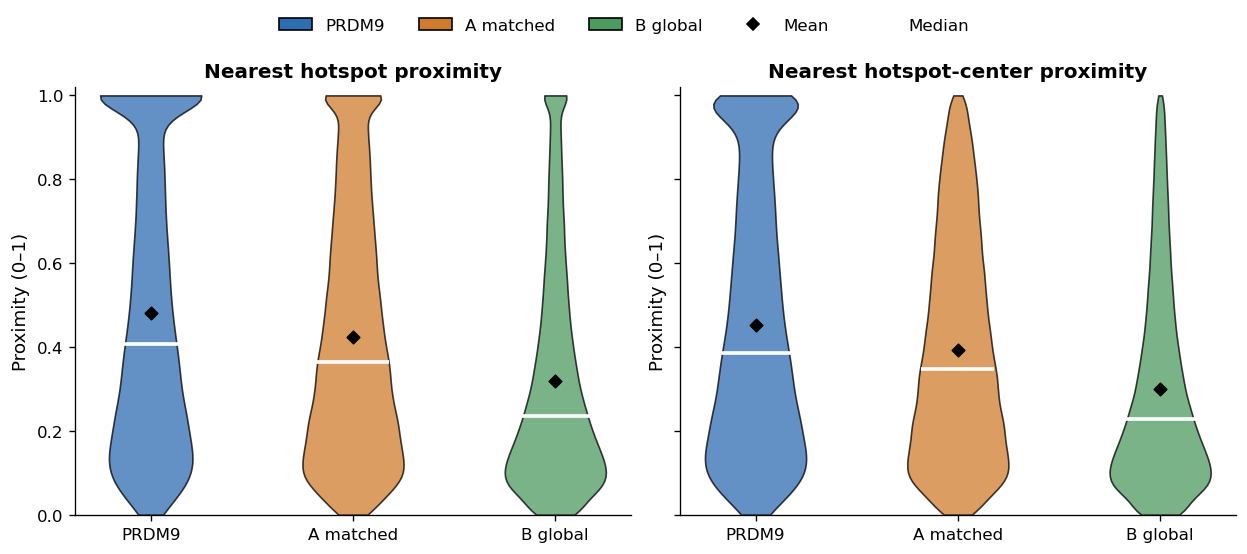

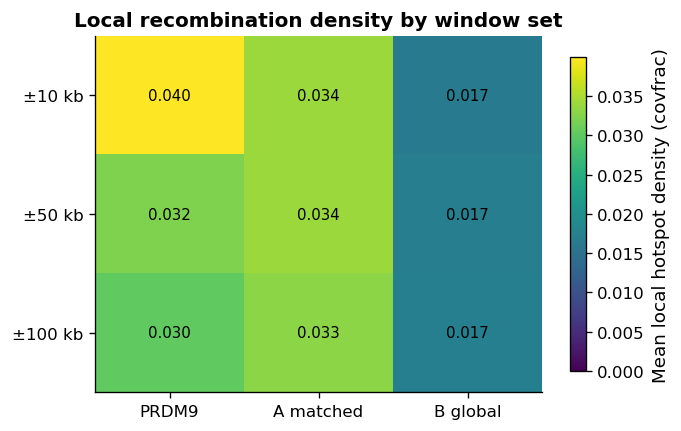

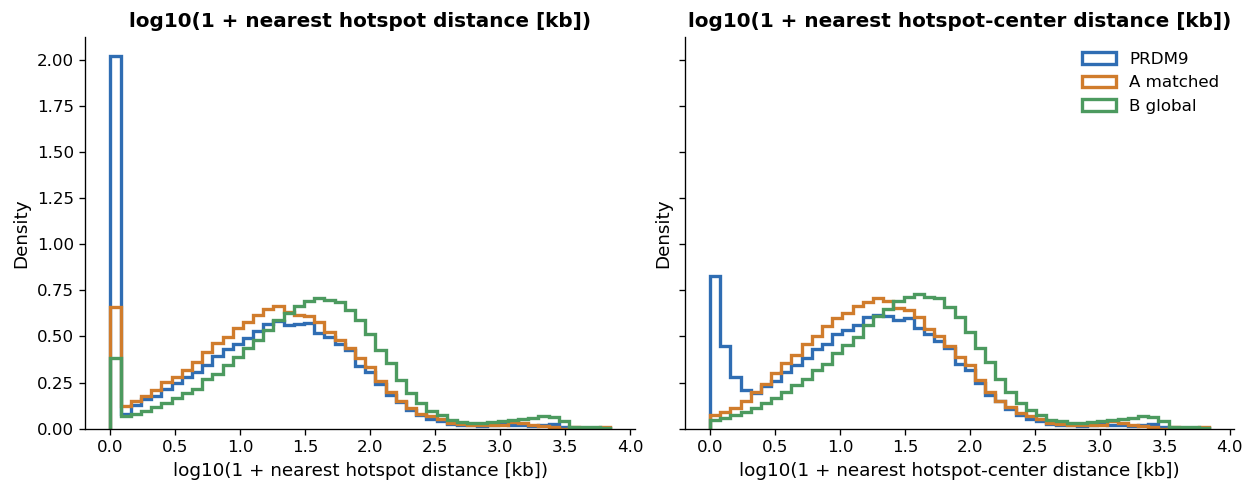

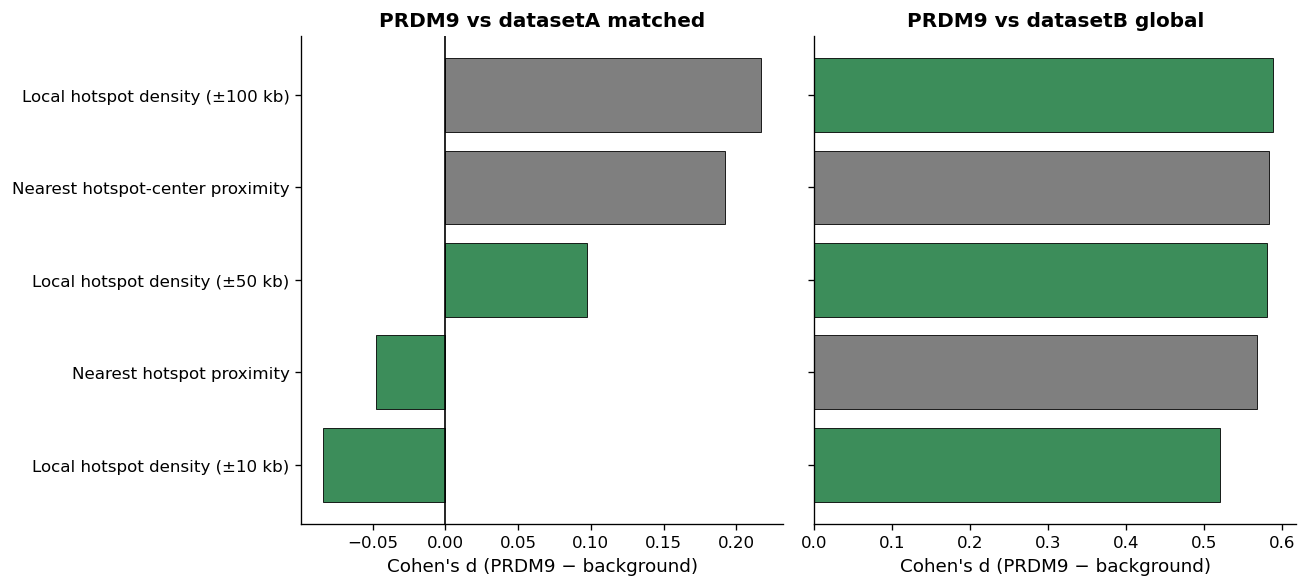

In [8]:

# ------------------------------------------------------------------
# Publication-style validation figures
# ------------------------------------------------------------------
plot_df = debug_out.copy()
plot_df["log10_nearest_hotspot_distance_kb_plus1"] = np.log10(plot_df["recombination__nearest_hotspot_distance_kb"] + 1.0)
plot_df["log10_nearest_hotspot_center_distance_kb_plus1"] = np.log10(
    plot_df["recombination__nearest_hotspot_center_distance_kb"] + 1.0
)

# 1) Proximity distributions
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharey=True)
for ax, feat, title in [
    (axes[0], "recombination__nearest_hotspot_proximity", "Nearest hotspot proximity"),
    (axes[1], "recombination__nearest_hotspot_center_proximity", "Nearest hotspot-center proximity"),
]:
    data = [plot_df.loc[plot_df["WindowSet"] == ws, feat].to_numpy(dtype=float) for ws in SET_ORDER]
    parts = ax.violinplot(data, positions=np.arange(1, len(SET_ORDER) + 1), showmeans=False, showmedians=False, showextrema=False)
    for i, body in enumerate(parts["bodies"]):
        body.set_facecolor(SET_COLORS[SET_ORDER[i]])
        body.set_edgecolor("black")
        body.set_alpha(0.75)

    medians = [np.median(d) for d in data]
    means = [np.mean(d) for d in data]
    for i, (m, mu) in enumerate(zip(medians, means), start=1):
        ax.scatter(i, mu, marker="D", s=28, color="black", zorder=3)
        ax.hlines(m, i - 0.18, i + 0.18, color="white", linewidth=2.2, zorder=4)

    ax.set_xticks(np.arange(1, len(SET_ORDER) + 1))
    ax.set_xticklabels([SET_LABELS[x] for x in SET_ORDER], rotation=0)
    ax.set_ylim(0, 1.02)
    ax.set_ylabel("Proximity (0–1)")
    ax.set_title(title)

legend_handles = [
    Patch(facecolor=SET_COLORS[ws], edgecolor="black", label=SET_LABELS[ws]) for ws in SET_ORDER
]
legend_handles.append(Line2D([0], [0], marker="D", color="black", linestyle="None", markersize=5, label="Mean"))
legend_handles.append(Line2D([0], [0], color="white", linewidth=2.2, label="Median"))
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=5)
fig.tight_layout()
fig.savefig(FIGDIR / "recombination_proximity_violin.png", bbox_inches="tight")
plt.show()

# 2) Local density heatmap
density_mean_mat = pd.DataFrame(
    {
        ws: [
            plot_df.loc[plot_df["WindowSet"] == ws, f"recombination__density_covfrac_{rad // 1000}kb"].mean()
            for rad in RADII_BP
        ]
        for ws in SET_ORDER
    },
    index=[f"±{rad // 1000} kb" for rad in RADII_BP]
)

fig, ax = plt.subplots(figsize=(5.8, 3.7))
im = ax.imshow(density_mean_mat.to_numpy(dtype=float), aspect="auto", vmin=0, vmax=max(1e-6, density_mean_mat.to_numpy(dtype=float).max()))
ax.set_xticks(np.arange(len(SET_ORDER)))
ax.set_xticklabels([SET_LABELS[x] for x in SET_ORDER])
ax.set_yticks(np.arange(len(RADII_BP)))
ax.set_yticklabels(density_mean_mat.index.tolist())
for i in range(density_mean_mat.shape[0]):
    for j in range(density_mean_mat.shape[1]):
        val = density_mean_mat.iloc[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=9)
cbar = fig.colorbar(im, ax=ax, shrink=0.88)
cbar.set_label("Mean local hotspot density (covfrac)")
ax.set_title("Local recombination density by window set")
fig.tight_layout()
fig.savefig(FIGDIR / "recombination_density_heatmap.png", bbox_inches="tight")
plt.show()

# 3) Raw distance sanity plot (log-scaled QC)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for ax, feat, title in [
    (axes[0], "log10_nearest_hotspot_distance_kb_plus1", "log10(1 + nearest hotspot distance [kb])"),
    (axes[1], "log10_nearest_hotspot_center_distance_kb_plus1", "log10(1 + nearest hotspot-center distance [kb])"),
]:
    bins = np.linspace(0, plot_df[feat].max(), 50)
    for ws in SET_ORDER:
        ax.hist(
            plot_df.loc[plot_df["WindowSet"] == ws, feat],
            bins=bins,
            density=True,
            histtype="step",
            linewidth=2.0,
            label=SET_LABELS[ws],
            color=SET_COLORS[ws],
        )
    ax.set_xlabel(title)
    ax.set_ylabel("Density")
    ax.set_title(title)

axes[1].legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGDIR / "recombination_raw_distance_qc.png", bbox_inches="tight")
plt.show()

# 4) PRDM9/background effect-size summary
effect_plot = effect_df.copy()
effect_plot["feature_label"] = effect_plot["feature"].map(pretty_feature_name)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 5.0), sharey=True)
for ax, comp in zip(axes, ["prdm9_vs_datasetA_matched", "prdm9_vs_datasetB_global"]):
    sub = effect_plot.loc[effect_plot["comparison"] == comp].copy()
    sub = sub.sort_values("cohens_d", ascending=True)
    y = np.arange(len(sub))
    colors = ["#7f7f7f" if "density" not in f else "#3c8d5a" for f in sub["feature"]]
    ax.barh(y, sub["cohens_d"].to_numpy(dtype=float), color=colors, edgecolor="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["feature_label"].tolist())
    ax.set_xlabel("Cohen's d (PRDM9 − background)")
    ax.set_title(comp.replace("prdm9_vs_", "PRDM9 vs ").replace("_", " "))
fig.tight_layout()
fig.savefig(FIGDIR / "recombination_effect_summary.png", bbox_inches="tight")
plt.show()


In [9]:

# ------------------------------------------------------------------
# Compact on-notebook summaries
# ------------------------------------------------------------------
display(hotspot_meta_df)
display(summary_df)
display(effect_df)

top_summary = (
    effect_df.loc[:, ["comparison", "feature", "prdm9_mean", "background_mean", "mean_ratio", "cohens_d"]]
    .copy()
)
top_summary["feature"] = top_summary["feature"].map(pretty_feature_name)
display(top_summary.sort_values(["comparison", "cohens_d"], ascending=[True, False]).reset_index(drop=True))

console.print(Panel.fit(
    "\n".join([
        "[bold green]Recombination production notebook completed[/bold green]",
        f"Main features: {ALL_PARQUET}",
        f"Debug features: {DEBUG_PARQUET}",
        f"Summary table: {SUMMARY_TABLE}",
        f"Effect table: {EFFECT_TABLE}",
        f"Figures: {FIGDIR}",
        f"Log: {LOG_PATH}",
    ]),
    title="Outputs"
))


,path,n_raw_rows,n_after_basic_qc,n_after_exact_dedup,n_merged_hotspots,median_hotspot_length_bp,mean_hotspot_length_bp,chromosomes_present
0,meiotic_recombination/meiotic_recombination_DS...,37481,37475,37475,37458,1378.0,1497.888889,"[chr1, chr10, chr11, chr12, chr13, chr14, chr1..."


,WindowSet,feature,n,mean,median,std,q05,q95
0,prdm9,recombination__nearest_hotspot_proximity,60580,0.480641,0.407232,0.327266,0.058608,1.000000
1,prdm9,recombination__nearest_hotspot_center_proximity,60580,0.452591,0.387282,0.305552,0.058257,0.986096
2,prdm9,recombination__density_covfrac_10kb,60580,0.039936,0.000000,0.062545,0.000000,0.163144
3,prdm9,recombination__density_covfrac_50kb,60580,0.032155,0.022320,0.035817,0.000000,0.104249
4,prdm9,recombination__density_covfrac_100kb,60580,0.030233,0.021165,0.030620,0.000000,0.092525
5,datasetA_matched,recombination__nearest_hotspot_proximity,181740,0.423502,0.364983,0.287272,0.054030,0.984349
6,datasetA_matched,recombination__nearest_hotspot_center_proximity,181740,0.393914,0.348365,0.257672,0.053684,0.870246
7,datasetA_matched,recombination__density_covfrac_10kb,181740,0.033985,0.000000,0.060510,0.000000,0.156292
8,datasetA_matched,recombination__density_covfrac_50kb,181740,0.033970,0.022440,0.038721,0.000000,0.114159
9,datasetA_matched,recombination__density_covfrac_100kb,181740,0.033016,0.021885,0.033931,0.000000,0.102904


,comparison,feature,prdm9_mean,background_mean,mean_difference,mean_ratio,cohens_d
0,prdm9_vs_datasetA_matched,recombination__nearest_hotspot_proximity,0.480641,0.423502,0.057139,1.134920,0.191886
1,prdm9_vs_datasetA_matched,recombination__nearest_hotspot_center_proximity,0.452591,0.393914,0.058678,1.148961,0.216973
2,prdm9_vs_datasetA_matched,recombination__density_covfrac_10kb,0.039936,0.033985,0.005951,1.175104,0.097515
3,prdm9_vs_datasetA_matched,recombination__density_covfrac_50kb,0.032155,0.033970,-0.001815,0.946567,-0.047746
4,prdm9_vs_datasetA_matched,recombination__density_covfrac_100kb,0.030233,0.033016,-0.002783,0.915700,-0.083999
5,prdm9_vs_datasetB_global,recombination__nearest_hotspot_proximity,0.480641,0.320776,0.159864,1.498366,0.568358
6,prdm9_vs_datasetB_global,recombination__nearest_hotspot_center_proximity,0.452591,0.301966,0.150625,1.498814,0.583548
7,prdm9_vs_datasetB_global,recombination__density_covfrac_10kb,0.039936,0.016594,0.023342,2.406599,0.520589
8,prdm9_vs_datasetB_global,recombination__density_covfrac_50kb,0.032155,0.017068,0.015086,1.883880,0.581133
9,prdm9_vs_datasetB_global,recombination__density_covfrac_100kb,0.030233,0.017163,0.013070,1.761518,0.588717


,comparison,feature,prdm9_mean,background_mean,mean_ratio,cohens_d
0,prdm9_vs_datasetA_matched,Nearest hotspot-center proximity,0.452591,0.393914,1.148961,0.216973
1,prdm9_vs_datasetA_matched,Nearest hotspot proximity,0.480641,0.423502,1.134920,0.191886
2,prdm9_vs_datasetA_matched,Local hotspot density (±10 kb),0.039936,0.033985,1.175104,0.097515
3,prdm9_vs_datasetA_matched,Local hotspot density (±50 kb),0.032155,0.033970,0.946567,-0.047746
4,prdm9_vs_datasetA_matched,Local hotspot density (±100 kb),0.030233,0.033016,0.915700,-0.083999
5,prdm9_vs_datasetB_global,Local hotspot density (±100 kb),0.030233,0.017163,1.761518,0.588717
6,prdm9_vs_datasetB_global,Nearest hotspot-center proximity,0.452591,0.301966,1.498814,0.583548
7,prdm9_vs_datasetB_global,Local hotspot density (±50 kb),0.032155,0.017068,1.883880,0.581133
8,prdm9_vs_datasetB_global,Nearest hotspot proximity,0.480641,0.320776,1.498366,0.568358
9,prdm9_vs_datasetB_global,Local hotspot density (±10 kb),0.039936,0.016594,2.406599,0.520589


╭────────────────────────────────────────────── Outputs ──────────────────────────────────────────────╮
│ Recombination production notebook completed                                                         │
│ Main features: data_prdm9_recombination_production/features/recombination_features.parquet          │
│ Debug features: data_prdm9_recombination_production/features/recombination_features_with_qc.parquet │
│ Summary table: data_prdm9_recombination_production/tables/recombination_windowset_summary.tsv       │
│ Effect table: data_prdm9_recombination_production/tables/recombination_effect_summary.tsv           │
│ Figures: data_prdm9_recombination_production/figures                                                │
│ Log: data_prdm9_recombination_production/logs/recombination_feature_generation.log                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────╯